<a href="https://colab.research.google.com/github/Mariana8l8/Abstract_Factory/blob/main/Lab5_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №5. Інженерія даних для задачі кластеризації
Дані: Automobile (Imports-85), ті самі, що в лабораторних №3 і №4.
Задача без цільової змінної: розбити 205 автомобілів на групи схожих за характеристиками (K-Means).
Порівнюємо три представлення даних: **A** — усі ознаки, **B** — відібрані ознаки, **C** — PCA.

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib

IN_NOTEBOOK = globals().get("IN_NOTEBOOK", False)
if not IN_NOTEBOOK:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score,
                             silhouette_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj.to_string() if hasattr(obj, "to_string") else obj)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

RANDOM_STATE = 42
BASE = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
OUT = BASE / "output"
OUT.mkdir(exist_ok=True)
DATA_PATH = next(p for p in [BASE / "Automobile_data.csv", BASE.parent / "lab3" / "Automobile_data.csv",
                             Path("Automobile_data.csv")] if p.exists())
SUMMARY = {}
PALETTE = ["#4C78A8", "#F58518", "#54A24B", "#E45756", "#B279A2", "#72B7B2"]


def save(name):
    plt.tight_layout()
    plt.savefig(OUT / name, dpi=150, bbox_inches="tight")
    plt.show()
    if not IN_NOTEBOOK:
        plt.close()

## Завдання 1. Підготовка даних за результатами EDA

In [ ]:
df_raw = pd.read_csv(DATA_PATH)
df = df_raw.replace("?", np.nan)                       # '?' — позначення пропусків
numeric_all = ["normalized-losses", "wheel-base", "length", "width", "height", "curb-weight", "engine-size",
               "bore", "stroke", "compression-ratio", "horsepower", "peak-rpm", "city-mpg", "highway-mpg", "price"]
for c in numeric_all:
    df[c] = pd.to_numeric(df[c], errors="coerce")

print("Розмір:", df.shape, "| дублікатів:", int(df.duplicated().sum()))
df = df.drop_duplicates().reset_index(drop=True)
print("Пропуски:", df.isna().sum()[lambda s: s > 0].to_dict())
print("Викиди (price, engine-size, compression-ratio) за EDA — реальні автомобілі та дизелі, тому залишаємо.")

# symboling — страховий рейтинг, normalized-losses — страхова величина з 20 % пропусків.
# Це не технічні характеристики авто, тому в кластеризації не беруть участі.
# symboling збережемо окремо, щоб після кластеризації перевірити, чи кластери мають зв'язок із ризиком.
external_symboling = df["symboling"].copy()
DROP_FEATURES = ["symboling", "normalized-losses"]
X = df.drop(columns=DROP_FEATURES)

numeric_features = [c for c in numeric_all if c in X.columns]
categorical_features = [c for c in X.columns if c not in numeric_features]
print(f"\nПочаткових колонок: {df_raw.shape[1]} → ознак для кластеризації: {X.shape[1]} "
      f"(числових {len(numeric_features)}, категорійних {len(categorical_features)})")
SUMMARY.update(raw_columns=int(df_raw.shape[1]), n_features=int(X.shape[1]), n_numeric=len(numeric_features),
               n_categorical=len(categorical_features), rows=int(len(df)))

Розмір: (205, 26) | дублікатів: 0
Пропуски: {'normalized-losses': 41, 'num-of-doors': 2, 'bore': 4, 'stroke': 4, 'horsepower': 2, 'peak-rpm': 2, 'price': 4}
Викиди (price, engine-size, compression-ratio) за EDA — реальні автомобілі та дизелі, тому залишаємо.

Початкових колонок: 26 → ознак для кластеризації: 24 (числових 14, категорійних 10)


## Завдання 2. Підготовка числових і категорійних ознак
K-Means рахує відстані між об'єктами. Якщо ознаки не масштабувати, ті, що мають великі числа
(price, curb-weight, peak-rpm), повністю переважать над рештою.

In [ ]:
raw_var = X[numeric_features].var()
share = (raw_var / raw_var.sum() * 100).sort_values(ascending=False)
print("Частка дисперсії (внесок у відстані) без масштабування, %:")
display(share.round(2).head(5).to_frame("частка, %"))
print("Після StandardScaler кожна ознака має дисперсію 1, тобто внесок ≈", round(100 / len(numeric_features), 1), "%.")
SUMMARY["unscaled_top_share"] = share.round(2).head(3).to_dict()

# Що було б без масштабування? Порівняємо кластери K-Means (k=2) на сирих і на стандартизованих даних
raw_num = SimpleImputer(strategy="median").fit_transform(X[numeric_features])
scaled_num = StandardScaler().fit_transform(raw_num)
labels_raw = KMeans(2, n_init=10, random_state=RANDOM_STATE).fit_predict(raw_num)
labels_scaled = KMeans(2, n_init=10, random_state=RANDOM_STATE).fit_predict(scaled_num)
ari_scale = adjusted_rand_score(labels_raw, labels_scaled)
print(f"ARI між розбиттям без масштабування і зі стандартизацією: {ari_scale:.3f}")
SUMMARY["ari_scaled_vs_raw"] = round(float(ari_scale), 3)


def make_preprocessor(num_cols, cat_cols, pca_components=None):
    num_steps = [("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]
    if pca_components is not None:
        num_steps.append(("pca", PCA(n_components=pca_components, svd_solver="full", random_state=RANDOM_STATE)))
    parts = []
    if num_cols:
        parts.append(("num", Pipeline(num_steps), list(num_cols)))
    if cat_cols:
        parts.append(("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                       ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]),
                      list(cat_cols)))
    return ColumnTransformer(parts)

Частка дисперсії (внесок у відстані) без масштабування, %:
Після StandardScaler кожна ознака має дисперсію 1, тобто внесок ≈ 7.1 %.
ARI між розбиттям без масштабування і зі стандартизацією: 0.221


,"частка, %"
price,99.21
curb-weight,0.43
peak-rpm,0.36
engine-size,0.00
horsepower,0.00


## Завдання 3. Формування наборів ознак
### Набір B — відбір ознак (кореляції, дублювання, низька варіативність)

In [ ]:
# 1) Числові ознаки, що дублюють одна одну: поки є пара з |r| ≥ 0.85, видаляємо ту ознаку пари,
#    яка в середньому найсильніше корелює з рештою.
CORR_THR = 0.85
corr = X[numeric_features].corr().abs()
kept_num, dropped_num = list(numeric_features), []
while True:
    sub = corr.loc[kept_num, kept_num].copy()
    for f in kept_num:
        sub.loc[f, f] = 0.0
    bad = [(a, b) for a in kept_num for b in kept_num if a < b and sub.loc[a, b] >= CORR_THR]
    if not bad:
        break
    involved = sorted({f for pair in bad for f in pair}, key=lambda f: -sub.loc[f].mean())
    worst = involved[0]
    partner = max((b if a == worst else a for a, b in bad if worst in (a, b)), key=lambda f: sub.loc[worst, f])
    dropped_num.append((worst, f"|r| = {sub.loc[worst, partner]:.2f} з {partner}; середня |r| з рештою {sub.loc[worst].mean():.2f}"))
    kept_num.remove(worst)
print("Числові ознаки, вилучені як надлишкові (дублюють інформацію):")
for f, why in dropped_num:
    print(f"  - {f}: {why}")
print("Числові ознаки у наборі B:", kept_num)

# 2) Низька варіативність: ознаки, де одна категорія займає ≥ 95 % рядків
cv = (X[numeric_features].std() / X[numeric_features].mean()).abs().sort_values()
print("\nМінімальний коефіцієнт варіації числових ознак:", cv.head(2).round(3).to_dict(), "→ жодна числова ознака не є сталою")
near_constant = [c for c in categorical_features if X[c].value_counts(normalize=True).iloc[0] >= 0.95]
print("Майже сталі категорійні:", near_constant, {c: round(X[c].value_counts(normalize=True).iloc[0], 3) for c in near_constant})


# 3) Дублювання між категорійними ознаками (V Крамера)
def cramers_v(a, b):
    t = pd.crosstab(a, b)
    chi2 = chi2_contingency(t)[0]
    n = t.values.sum()
    return float(np.sqrt(chi2 / (n * (min(t.shape) - 1))))


redundant_cat = []
for i, a in enumerate(categorical_features):
    for b in categorical_features[i + 1:]:
        v = cramers_v(X[a], X[b])
        if v >= 0.90:
            drop = a if X[a].nunique() > X[b].nunique() else b
            redundant_cat.append((drop, f"V Крамера = {v:.2f} з {b if drop == a else a}"))
print("Категорійні ознаки-дублікати:", redundant_cat)

# 4) Категорійна ознака з дуже високою кардинальністю: 22 марки дали б 22 бінарні колонки й переважили б числові
high_card = [c for c in categorical_features if X[c].nunique() > 15]
print("Високу кардинальність мають:", high_card)

drop_cat = list(dict.fromkeys(near_constant + [c for c, _ in redundant_cat] + high_card))
kept_cat = [c for c in categorical_features if c not in drop_cat]
print("\nКатегорійні у наборі B:", kept_cat)
print("Вилучені категорійні:", drop_cat)
selected_features = kept_num + kept_cat
print(f"\nНабір B: {len(selected_features)} із {X.shape[1]} ознак")

decisions = pd.DataFrame(
    [(f, "числова", "вилучено", why) for f, why in dropped_num] +
    [(c, "категорійна", "вилучено", "майже стала (98.5 % — front)") for c in near_constant] +
    [(c, "категорійна", "вилучено", why) for c, why in redundant_cat] +
    [(c, "категорійна", "вилучено", f"висока кардинальність ({X[c].nunique()} категорій)") for c in high_card],
    columns=["ознака", "тип", "рішення", "причина"])
display(decisions)
decisions.to_csv(OUT / "feature_selection_B.csv", index=False)
SUMMARY.update(B_features=selected_features, B_dropped_num=[f for f, _ in dropped_num], B_dropped_cat=drop_cat,
               B_num=kept_num, B_cat=kept_cat)

Числові ознаки, вилучені як надлишкові (дублюють інформацію):
  - curb-weight: |r| = 0.88 з length; середня |r| з рештою 0.57
  - length: |r| = 0.87 з wheel-base; середня |r| з рештою 0.51
  - engine-size: |r| = 0.87 з price; середня |r| з рештою 0.46
  - highway-mpg: |r| = 0.97 з city-mpg; середня |r| з рештою 0.43
Числові ознаки у наборі B: ['wheel-base', 'width', 'height', 'bore', 'stroke', 'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg', 'price']

Мінімальний коефіцієнт варіації числових ознак: {'width': 0.033, 'height': 0.045} → жодна числова ознака не є сталою
Майже сталі категорійні: ['engine-location'] {'engine-location': np.float64(0.985)}
Категорійні ознаки-дублікати: [('fuel-system', 'V Крамера = 1.00 з fuel-type')]
Високу кардинальність мають: ['make']

Категорійні у наборі B: ['fuel-type', 'aspiration', 'num-of-doors', 'body-style', 'drive-wheels', 'engine-type', 'num-of-cylinders']
Вилучені категорійні: ['engine-location', 'fuel-system', 'make']

Набір B: 17 із 

,ознака,тип,рішення,причина
0,curb-weight,числова,вилучено,|r| = 0.88 з length; середня |r| з рештою 0.57
1,length,числова,вилучено,|r| = 0.87 з wheel-base; середня |r| з рештою 0.51
2,engine-size,числова,вилучено,|r| = 0.87 з price; середня |r| з рештою 0.46
3,highway-mpg,числова,вилучено,|r| = 0.97 з city-mpg; середня |r| з рештою 0.43
4,engine-location,категорійна,вилучено,майже стала (98.5 % — front)
5,fuel-system,категорійна,вилучено,V Крамера = 1.00 з fuel-type
6,make,категорійна,вилучено,висока кардинальність (22 категорій)


### Набір C — PCA на стандартизованих числових ознаках

90 % дисперсії: 6 компонент; 95 %: 8 компонент (із 14 числових ознак)


,PC,explained_variance_ratio,cumulative
0,PC1,0.5272,0.5272
1,PC2,0.1660,0.6932
2,PC3,0.0844,0.7776
3,PC4,0.0636,0.8412
4,PC5,0.0438,0.8850
5,PC6,0.0317,0.9167
6,PC7,0.0252,0.9419
7,PC8,0.0206,0.9625
8,PC9,0.0128,0.9753
9,PC10,0.0084,0.9837


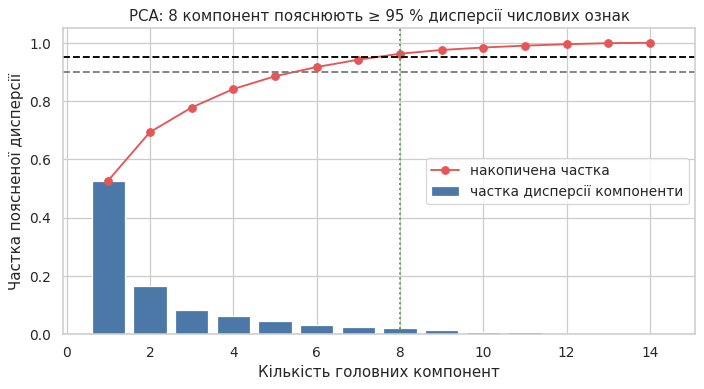

In [ ]:
Z_num = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(X[numeric_features]))
pca_full = PCA(svd_solver="full", random_state=RANDOM_STATE).fit(Z_num)
evr, cum = pca_full.explained_variance_ratio_, np.cumsum(pca_full.explained_variance_ratio_)
pca_table = pd.DataFrame({"PC": [f"PC{i+1}" for i in range(len(evr))], "explained_variance_ratio": evr.round(4),
                          "cumulative": cum.round(4)})
display(pca_table)
pca_table.to_csv(OUT / "pca_variance.csv", index=False)
k90, k95 = int(np.argmax(cum >= 0.90) + 1), int(np.argmax(cum >= 0.95) + 1)
print(f"90 % дисперсії: {k90} компонент; 95 %: {k95} компонент (із {len(numeric_features)} числових ознак)")
SUMMARY.update(pca_k90=k90, pca_k95=k95, pca_pc1=round(float(evr[0]), 3), pca_pc2=round(float(evr[1]), 3),
               pca_cum_k95=round(float(cum[k95 - 1]), 3))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(range(1, len(evr) + 1), evr, color="#4C78A8", label="частка дисперсії компоненти")
ax.plot(range(1, len(evr) + 1), cum, "o-", color="#E45756", label="накопичена частка")
ax.axhline(0.90, ls="--", color="gray"); ax.axhline(0.95, ls="--", color="black")
ax.axvline(k95, ls=":", color="#54A24B")
ax.set_xlabel("Кількість головних компонент"); ax.set_ylabel("Частка поясненої дисперсії")
ax.set_title(f"PCA: {k95} компонент пояснюють ≥ 95 % дисперсії числових ознак")
ax.legend(loc="center right")
save("01_pca_variance.png")

In [ ]:
prep_A = make_preprocessor(numeric_features, categorical_features)
prep_B = make_preprocessor(kept_num, kept_cat)
prep_C = make_preprocessor(numeric_features, [], pca_components=0.95)
representations = {
    "A: усі ознаки": (prep_A, X),
    "B: відібрані ознаки": (prep_B, X[selected_features]),
    "C: PCA": (prep_C, X[numeric_features]),
}
matrices = {}
for name, (prep, data) in representations.items():
    matrices[name] = prep.fit_transform(data)
dims = pd.DataFrame({"вхідних ознак": [X.shape[1], len(selected_features), len(numeric_features)],
                     "розмірність простору для K-Means": [m.shape[1] for m in matrices.values()]},
                    index=list(matrices))
display(dims)
dims.to_csv(OUT / "representation_dimensions.csv")
SUMMARY["dims"] = {k: int(v.shape[1]) for k, v in matrices.items()}

,вхідних ознак,розмірність простору для K-Means
A: усі ознаки,24,74
B: відібрані ознаки,17,38
C: PCA,14,8


## Завдання 4. Визначення кількості кластерів (k = 2…10): Elbow + Silhouette

Оптимальне k за максимумом Silhouette: {'A: усі ознаки': 2, 'B: відібрані ознаки': 2, 'C: PCA': 2}


representation,A: усі ознаки,B: відібрані ознаки,C: PCA
k,,,
2,0.268,0.262,0.338
3,0.227,0.254,0.226
4,0.175,0.227,0.248
5,0.180,0.236,0.257
6,0.181,0.176,0.273
7,0.203,0.196,0.292
8,0.226,0.186,0.323
9,0.219,0.223,0.326
10,0.217,0.205,0.319


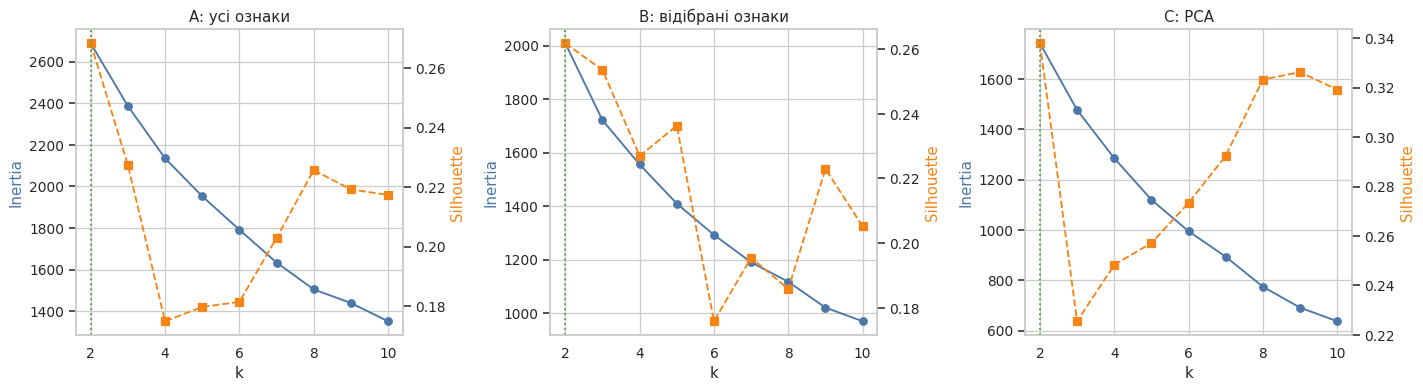

In [ ]:
K_RANGE = range(2, 11)
rows = []
for name, Z in matrices.items():
    for k in K_RANGE:
        km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Z)
        rows.append({"representation": name, "k": k, "inertia": km.inertia_,
                     "silhouette": silhouette_score(Z, km.labels_),
                     "davies_bouldin": davies_bouldin_score(Z, km.labels_),
                     "calinski_harabasz": calinski_harabasz_score(Z, km.labels_)})
k_table = pd.DataFrame(rows)
k_table.round(4).to_csv(OUT / "k_selection.csv", index=False)
display(k_table.pivot(index="k", columns="representation", values="silhouette").round(3))

best_k = {}
for name in matrices:
    sub = k_table[k_table["representation"] == name]
    best_k[name] = int(sub.loc[sub["silhouette"].idxmax(), "k"])
print("Оптимальне k за максимумом Silhouette:", best_k)
SUMMARY["best_k"] = best_k
SUMMARY["silhouette_by_k"] = {n: k_table[k_table["representation"] == n].set_index("k")["silhouette"].round(3).to_dict()
                              for n in matrices}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, name in zip(axes, matrices):
    sub = k_table[k_table["representation"] == name]
    ax.plot(sub["k"], sub["inertia"], "o-", color="#4C78A8")
    ax.set_xlabel("k"); ax.set_ylabel("Inertia", color="#4C78A8"); ax.set_title(name)
    ax2 = ax.twinx()
    ax2.plot(sub["k"], sub["silhouette"], "s--", color="#F58518")
    ax2.set_ylabel("Silhouette", color="#F58518"); ax2.grid(False)
    ax2.axvline(best_k[name], ls=":", color="#54A24B")
save("02_elbow_silhouette.png")

## Завдання 5–6. K-Means для трьох представлень та оцінювання якості
Однакові параметри алгоритму: `init="k-means++"`, `n_init=10`, `random_state=42`.

In [ ]:
models, labels, centers = {}, {}, {}
metric_rows = []
for name, Z in matrices.items():
    k = best_k[name]
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=RANDOM_STATE).fit(Z)
    models[name], labels[name], centers[name] = km, km.labels_, km.cluster_centers_
    metric_rows.append({"Модель": name, "k": k, "Розмірність": Z.shape[1], "Inertia": km.inertia_,
                        "Silhouette": silhouette_score(Z, km.labels_),
                        "Davies-Bouldin (менше = краще)": davies_bouldin_score(Z, km.labels_),
                        "Calinski-Harabasz": calinski_harabasz_score(Z, km.labels_),
                        "Розміри кластерів": ", ".join(str(int(v)) for v in np.bincount(km.labels_))})
metrics = pd.DataFrame(metric_rows).set_index("Модель")
display(metrics.round(3))
metrics.round(4).to_csv(OUT / "cluster_metrics.csv")
SUMMARY["metrics"] = metrics.round(4).reset_index().to_dict("records")

names = list(matrices)
ari = pd.DataFrame([[adjusted_rand_score(labels[a], labels[b]) for b in names] for a in names], index=names, columns=names)
print("\nУзгодженість розбиттів (Adjusted Rand Index):")
display(ari.round(3))
ari.round(4).to_csv(OUT / "cluster_agreement_ari.csv")
SUMMARY["ari"] = ari.round(3).to_dict()

assignments = df[["make", "body-style", "fuel-type", "price"]].copy()
for name in names:
    assignments["cluster_" + name[0]] = labels[name]
assignments.to_csv(OUT / "cluster_assignments.csv", index=False)


Узгодженість розбиттів (Adjusted Rand Index):


,k,Розмірність,Inertia,Silhouette,Davies-Bouldin (менше = краще),Calinski-Harabasz,Розміри кластерів
Модель,,,,,,,
A: усі ознаки,2,74,2688.167,0.268,1.470,84.972,"124, 81"
B: відібрані ознаки,2,38,2008.195,0.262,1.629,65.794,"67, 138"
C: PCA,2,8,1741.044,0.338,1.191,119.067,"129, 76"


,A: усі ознаки,B: відібрані ознаки,C: PCA
A: усі ознаки,1.000,0.709,0.904
B: відібрані ознаки,0.709,1.000,0.794
C: PCA,0.904,0.794,1.000


## Завдання 7. Візуалізація кластерів у площині PC1 × PC2

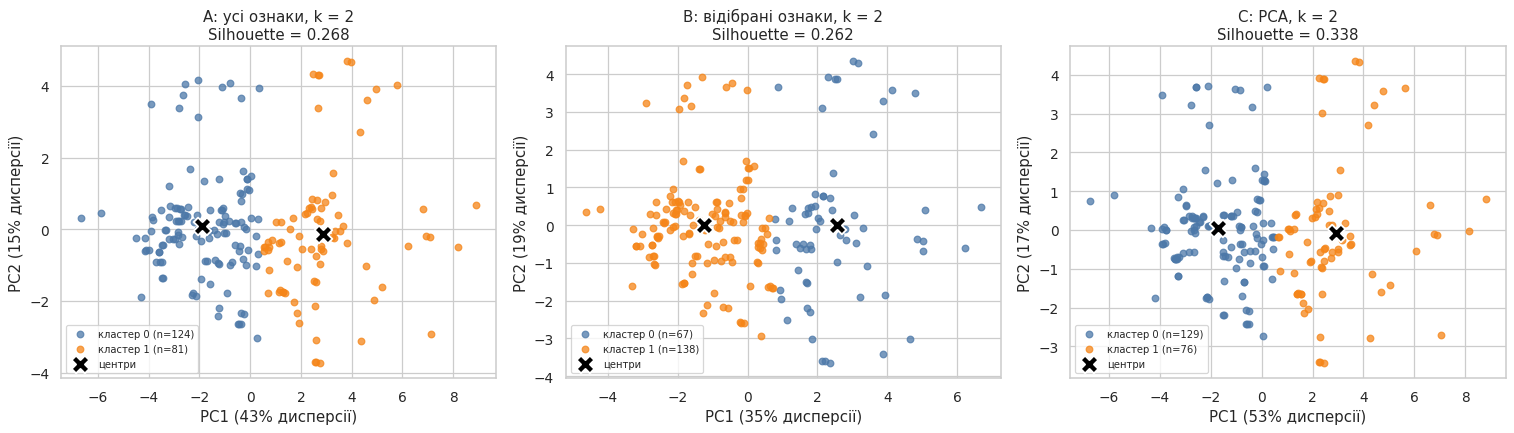

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, name in zip(axes, names):
    Z, km = matrices[name], models[name]
    if name.startswith("C"):
        P, C = Z[:, :2], km.cluster_centers_[:, :2]
        evr2 = pca_full.explained_variance_ratio_[:2]
    else:
        p2 = PCA(n_components=2, random_state=RANDOM_STATE).fit(Z)
        P, C, evr2 = p2.transform(Z), p2.transform(km.cluster_centers_), p2.explained_variance_ratio_
    for cl in range(km.n_clusters):
        m = labels[name] == cl
        ax.scatter(P[m, 0], P[m, 1], s=28, alpha=0.75, color=PALETTE[cl], label=f"кластер {cl} (n={m.sum()})")
    ax.scatter(C[:, 0], C[:, 1], marker="X", s=200, c="black", edgecolor="white", linewidth=1.5, label="центри")
    ax.set_xlabel(f"PC1 ({evr2[0]*100:.0f}% дисперсії)"); ax.set_ylabel(f"PC2 ({evr2[1]*100:.0f}% дисперсії)")
    ax.set_title(f"{name}, k = {km.n_clusters}\nSilhouette = {silhouette_score(Z, labels[name]):.3f}")
    ax.legend(fontsize=8)
save("03_clusters_pc1_pc2.png")

## Завдання 8. Профіль кластерів
Вибираємо представлення з найвищим Silhouette (правило: максимум Silhouette; при близьких значеннях — простіша модель).

In [ ]:
final_name = metrics["Silhouette"].idxmax()
print("Представлення для фінального pipeline:", final_name)
SUMMARY["final_representation"] = final_name
df_c = df.copy()
df_c["cluster"] = labels[final_name]
K = int(best_k[final_name])

profile_num = ["price", "horsepower", "engine-size", "curb-weight", "length", "wheel-base", "city-mpg", "compression-ratio", "peak-rpm"]
prof = df_c.groupby("cluster")[profile_num].median().round(1)
prof.insert(0, "n", df_c["cluster"].value_counts().sort_index())
prof.insert(1, "%", (df_c["cluster"].value_counts(normalize=True).sort_index() * 100).round(1))
display(prof)
prof.to_csv(OUT / "cluster_profile_numeric.csv")

cat_profile = {}
for c in ["fuel-type", "aspiration", "body-style", "drive-wheels", "num-of-cylinders", "make"]:
    ct = pd.crosstab(df_c["cluster"], df_c[c], normalize="index") * 100
    top = ct.idxmax(axis=1)
    cat_profile[c] = {int(cl): f"{top[cl]} ({ct.loc[cl, top[cl]]:.0f}%)" for cl in ct.index}
cat_prof = pd.DataFrame(cat_profile)
display(cat_prof)
cat_prof.to_csv(OUT / "cluster_profile_categorical.csv")

# які ознаки найбільше розрізняють кластери
disc_num = {}
for c in numeric_features:
    x = df_c[c]
    grand = x.mean()
    ssb = sum(len(g) * (g.mean() - grand) ** 2 for _, g in x.groupby(df_c["cluster"]))
    sst = ((x.dropna() - grand) ** 2).sum()
    disc_num[c] = ssb / sst
disc_cat = {c: cramers_v(df_c["cluster"], df_c[c]) for c in categorical_features}
disc = pd.concat([pd.Series(disc_num, name="сила зв'язку з кластером").to_frame().assign(тип="числова (η²)"),
                  pd.Series(disc_cat, name="сила зв'язку з кластером").to_frame().assign(тип="категорійна (V Крамера)")])
disc = disc.sort_values("сила зв'язку з кластером", ascending=False)
display(disc.head(10).round(3))
disc.round(4).to_csv(OUT / "cluster_discriminating_features.csv")
SUMMARY["top_discriminating"] = disc.head(8)["сила зв'язку з кластером"].round(3).to_dict()

# зовнішня перевірка: symboling у кластерах (у кластеризації не використовувався)
sym = pd.crosstab(df_c["cluster"], external_symboling, normalize="index").mul(100).round(1)
print("\nРозподіл symboling у кластерах, % (symboling у кластеризації не використовувався):")
display(sym)
sym.to_csv(OUT / "cluster_vs_symboling.csv")
SUMMARY["symboling_mean_by_cluster"] = external_symboling.groupby(df_c["cluster"]).mean().round(2).to_dict()

# приклади моделей у кожному кластері
examples = {int(cl): df_c[df_c["cluster"] == cl]["make"].value_counts().head(5).to_dict() for cl in range(K)}
print("Найчастіші марки в кластерах:", examples)
SUMMARY["cluster_top_makes"] = examples
SUMMARY["profile_numeric"] = prof.reset_index().to_dict("records")
SUMMARY["profile_categorical"] = cat_prof.reset_index().to_dict("records")

Представлення для фінального pipeline: C: PCA

Розподіл symboling у кластерах, % (symboling у кластеризації не використовувався):
Найчастіші марки в кластерах: {0: {'toyota': 25, 'mazda': 16, 'honda': 13, 'nissan': 12, 'subaru': 12}, 1: {'peugot': 11, 'volvo': 11, 'mercedes-benz': 8, 'toyota': 7, 'audi': 6}}


,n,%,price,horsepower,engine-size,curb-weight,length,wheel-base,city-mpg,compression-ratio,peak-rpm
cluster,,,,,,,,,,,
0,129,62.9,8189.0,76.0,98.0,2264.0,169.0,95.7,27.0,9.0,5200.0
1,76,37.1,17689.5,141.0,152.0,3054.0,186.7,103.9,19.0,9.0,5200.0


,fuel-type,aspiration,body-style,drive-wheels,num-of-cylinders,make
0,gas (92%),std (91%),sedan (43%),fwd (80%),four (95%),toyota (19%)
1,gas (87%),std (66%),sedan (53%),rwd (75%),four (47%),peugot (14%)


,сила зв'язку з кластером,тип
make,0.782,категорійна (V Крамера)
curb-weight,0.680,числова (η²)
fuel-system,0.633,категорійна (V Крамера)
num-of-cylinders,0.631,категорійна (V Крамера)
drive-wheels,0.604,категорійна (V Крамера)
width,0.537,числова (η²)
price,0.528,числова (η²)
horsepower,0.525,числова (η²)
engine-size,0.507,числова (η²)
length,0.502,числова (η²)


symboling,-2,-1,0,1,2,3
cluster,,,,,,
0,0.0,6.2,31.0,35.7,18.6,8.5
1,3.9,18.4,35.5,10.5,10.5,21.1


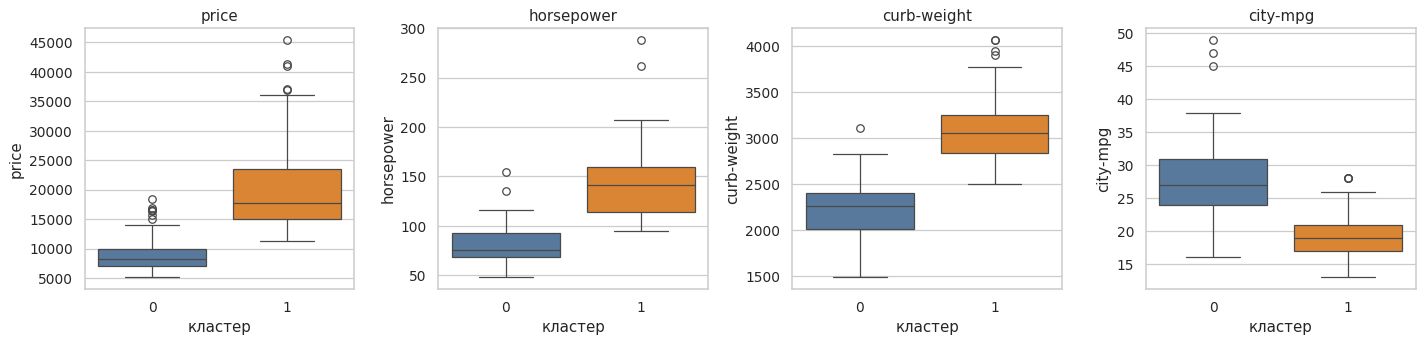

In [ ]:
cols = ["price", "horsepower", "curb-weight", "city-mpg"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, c in zip(axes, cols):
    sns.boxplot(data=df_c, x="cluster", y=c, palette=PALETTE[:K], ax=ax)
    ax.set_title(c); ax.set_xlabel("кластер")
save("04_cluster_profile_boxplots.png")

## Завдання 9. Порівняльний аналіз (числа для висновків)

In [ ]:
cmp = metrics[["k", "Розмірність", "Inertia", "Silhouette", "Davies-Bouldin (менше = краще)", "Calinski-Harabasz"]].round(3)
display(cmp)
print("Найвищий Silhouette:", metrics["Silhouette"].idxmax())
print("Найкращий (найменший) Davies-Bouldin:", metrics["Davies-Bouldin (менше = краще)"].idxmin())
print("Найвищий Calinski-Harabasz:", metrics["Calinski-Harabasz"].idxmax())
SUMMARY["best_by_metric"] = {"silhouette": metrics["Silhouette"].idxmax(),
                             "davies_bouldin": metrics["Davies-Bouldin (менше = краще)"].idxmin(),
                             "calinski_harabasz": metrics["Calinski-Harabasz"].idxmax()}

Найвищий Silhouette: C: PCA
Найкращий (найменший) Davies-Bouldin: C: PCA
Найвищий Calinski-Harabasz: C: PCA


,k,Розмірність,Inertia,Silhouette,Davies-Bouldin (менше = краще),Calinski-Harabasz
Модель,,,,,,
A: усі ознаки,2,74,2688.167,0.268,1.470,84.972
B: відібрані ознаки,2,38,2008.195,0.262,1.629,65.794
C: PCA,2,8,1741.044,0.338,1.191,119.067


## Завдання 10. Фінальний pipeline

In [ ]:
if final_name.startswith("A"):
    final_prep, final_cols = make_preprocessor(numeric_features, categorical_features), list(X.columns)
elif final_name.startswith("B"):
    final_prep, final_cols = make_preprocessor(kept_num, kept_cat), selected_features
else:
    final_prep, final_cols = make_preprocessor(numeric_features, [], pca_components=0.95), numeric_features

final_pipeline = Pipeline([("prep", final_prep),
                           ("kmeans", KMeans(n_clusters=K, init="k-means++", n_init=10, random_state=RANDOM_STATE))])
final_pipeline.fit(X[final_cols])
print(final_pipeline)
same = (final_pipeline.named_steps["kmeans"].labels_ == labels[final_name]).all()
print("\nЗбігається з експериментом:", bool(same))
new_car = X[final_cols].iloc[[0]]
print("Приклад: кластер для першого автомобіля набору:", int(final_pipeline.predict(new_car)[0]))

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler()),
                                                                  ('pca',
                                                                   PCA(n_components=0.95,
                                                                       random_state=42,
                                                                       svd_solver='full'))]),
                                                  ['wheel-base', 'length',
                                                   'width', 'height',
                                                   'curb-weight', 'engine-size',
   

In [ ]:
with open(OUT / "summary.json", "w", encoding="utf-8") as f:
    json.dump(SUMMARY, f, ensure_ascii=False, indent=2,
              default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("Готово. Результати збережено у", OUT)

Готово. Результати збережено у /home/claude/3.1-labs/Lab_Data_Engineering_Methods_and_Technologies/lab5/output
